# Midterm — Kaggle Challenge: Credit Score Prediction

**Goal:** predict the `Credit_Score` category (*Good*, *Poor*, *Standard*) of each credit application from a dataset with errors, inconsistencies and missing values.

**Structure:**
1. Understand the problem
2. Data preparation (cleaning + features)
3. Baseline
4. Model selection and experimentation
5. Final model and `submission.csv`

In [72]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
SEED = 42
DATA_DIR = "../csv/"          # folder with X_train, y_train, X_test and sample_submission
TARGET = 'Credit_Score'

In [73]:
train = pd.read_csv(DATA_DIR + 'X_train_Kaggle.csv', low_memory=False)
y_train_raw = pd.read_csv(DATA_DIR + 'y_train_Kaggle.csv')
test = pd.read_csv(DATA_DIR + 'X_test_Kaggle.csv', low_memory=False)
sample = pd.read_csv(DATA_DIR + 'sample_submission_credit.csv')

# The target comes in a separate file (same row order as X_train)
assert len(train) == len(y_train_raw)
train[TARGET] = y_train_raw[TARGET].values

print('train:', train.shape, '| test:', test.shape, '| sample:', sample.shape)
train.head()

train: (70000, 28) | test: (30000, 27) | sample: (30000, 2)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1d653,CUS_0xa037,February,Aruna Viswanathap,21,318-64-2372,Manager,151649.36,12823.446667,3,...,Good,358.17,38.252928,29 Years and 11 Months,No,224.703133,763.4809808066542,Low_spent_Large_value_payments,564.1605530687996,Poor
1,0x177f0,CUS_0x1aee,July,Klaymanp,26,065-68-6043,Accountant,100465.13999999998,8279.095000,4,...,Good,990.2,40.708250,32 Years and 9 Months,No,0.000000,155.12209196021695,High_spent_Large_value_payments,912.787408039783,Standard
2,0xb618,CUS_0x8d56,March,George Georgiopoulosv,37,063-47-6931,Engineer,43395.09,3562.257500,1,...,_,1103.7,35.041464,32 Years and 7 Months,NM,74.869250,178.811691303449,High_spent_Small_value_payments,362.5448082410094,Standard
3,0x150a5,CUS_0x8a8e,April,Yereth Rosend,34,#F%$D@*&8,Lawyer,80661.32,NaN,5,...,Standard,1482.15,33.109288,7 Years and 6 Months,Yes,135.562474,232.1346014840457,High_spent_Small_value_payments,547.4805911079858,Standard
4,0x19546,CUS_0x43d0,May,Camposb,3194,309-30-6070,Scientist,81506.32,7012.193333,7,...,Standard,933.67,27.513472,9 Years and 8 Months,NM,92.506250,318.73385010196097,High_spent_Small_value_payments,549.9792335289444,Standard


## Part 1 — Understand the problem

- **Features:** customer data (age, occupation, income), credit activity (accounts, cards, loans, delays, debt, utilization) and payment behaviour.
- **Target:** `Credit_Score` with 3 classes → **multiclass classification**.
- **Metric:** **ROC AUC** (multiclass, one-vs-rest). It measures how well the model *ranks* the samples of each class above the rest.

Credit_Score
Standard    0.533
Poor        0.288
Good        0.179
Name: proportion, dtype: float64


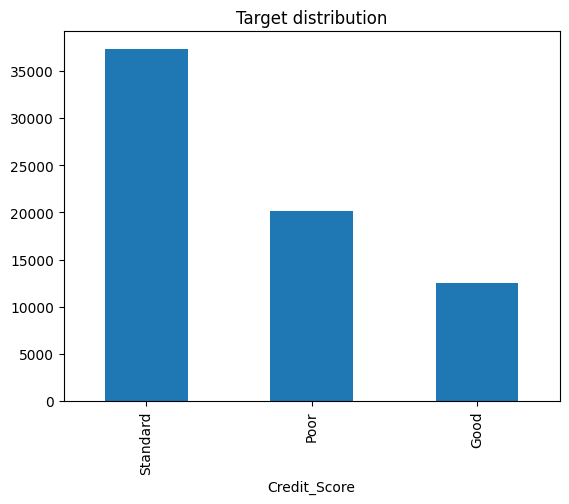

In [74]:
print(train[TARGET].value_counts(normalize=True).round(3))
train[TARGET].value_counts().plot(kind='bar', title='Target distribution');

In [75]:
# Missing values
train.isna().mean().sort_values(ascending=False).head(10).round(3)

Monthly_Inhand_Salary      0.150
Type_of_Loan               0.115
Name                       0.100
Credit_History_Age         0.090
Num_of_Delayed_Payment     0.070
Amount_invested_monthly    0.045
Num_Credit_Inquiries       0.020
Monthly_Balance            0.012
Month                      0.000
Age                        0.000
dtype: float64

In [76]:
# Examples of "garbage" in the columns: underscores, strange codes and impossible outliers
for c in ['Age', 'Annual_Income', 'Num_of_Loan', 'Num_Bank_Accounts', 'Occupation',
          'Credit_Mix', 'Payment_Behaviour', 'Amount_invested_monthly', 'Monthly_Balance']:
    print(f'{c:25s}', train[c].astype(str).sample(8, random_state=1).tolist())

Age                       ['20', '23', '41', '16', '46', '31', '40', '43']
Annual_Income             ['30783.88', '82339.36', '19078.99', '57877.95', '75868.8', '100791.57', '13351.83', '60040.5_']
Num_of_Loan               ['2', '4', '5', '5', '7', '1_', '2_', '7']
Num_Bank_Accounts         ['5', '7', '9', '8', '6', '2', '6', '7']
Occupation                ['Manager', 'Manager', 'Manager', '_______', 'Doctor', 'Architect', 'Architect', '_______']
Credit_Mix                ['Standard', '_', 'Bad', 'Standard', 'Bad', 'Good', 'Standard', 'Bad']
Payment_Behaviour         ['High_spent_Medium_value_payments', 'High_spent_Large_value_payments', 'High_spent_Medium_value_payments', '!@9#%8', 'High_spent_Medium_value_payments', 'High_spent_Medium_value_payments', 'Low_spent_Small_value_payments', 'High_spent_Large_value_payments']
Amount_invested_monthly   ['108.74425304685866', '97.61406798980722', '67.61022531819654', '170.18651131580245', '225.25783387486007', '343.25873006620344', '99.51425

In [77]:
# Temporal structure: each customer appears in several months
print('Rows per customer (train):', train.groupby('Customer_ID').size().describe()[['mean', 'min', 'max']].to_dict())
print('Train months:', train['Month'].unique())
print('Test months :', test['Month'].unique())
overlap = test['Customer_ID'].isin(train['Customer_ID']).mean()
print(f'Test rows whose customer also appears in train: {overlap:.1%}')

Rows per customer (train): {'mean': 5.600896143382942, 'min': 1.0, 'max': 8.0}
Train months: ['February' 'July' 'March' 'April' 'May' 'January' 'June' 'August']
Test months : ['February' 'January' 'April' 'August' 'March' 'May' 'June' 'July']
Test rows whose customer also appears in train: 99.9%


**Problems found:**
- Numbers stored as text with underscores (`"23_"`, `"__10000__"`), so pandas reads them as `object`.
- Impossible values / outliers (negative ages or thousands of years, 1000+ bank accounts, balances of `-3e26`).
- Garbage categories: `"_______"` in `Occupation`, `"_"` in `Credit_Mix`, `"!@9#%8"` in `Payment_Behaviour`, `"NM"` in `Payment_of_Min_Amount`.
- `Credit_History_Age` stored as text (`"22 Years and 1 Months"`).
- `Type_of_Loan` is a list of several loans inside a single string.
- Imbalanced classes (*Standard* dominates).
- **Key insight:** each customer appears in several months and their "static" data (age, income, occupation, number of accounts…) should be the same in all their records. This allows us to **fix errors using the other records of the same customer**.
- 99.9% of the test customers also appear in train: the Kaggle split was random by rows, not by customer.

## Part 2 — Data preparation

Train and test are concatenated **only for cleaning** (the target is never used, so there is no information leakage). This way each customer has all their records available to repair values, and both sets receive exactly the same transformations.

In [78]:
train['_is_train'] = 1
test['_is_train'] = 0
full = pd.concat([train, test], ignore_index=True)

MONTHS = {m: i for i, m in enumerate(['January', 'February', 'March', 'April', 'May', 'June', 'July',
                                      'August', 'September', 'October', 'November', 'December'], 1)}
full['Month_num'] = pd.to_numeric(full['Month'], errors='coerce').fillna(full['Month'].map(MONTHS))

### 2.1 Convert text to numbers and remove garbage categories

In [79]:
NUM_COLS = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
            'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment',
            'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Outstanding_Debt', 'Credit_Utilization_Ratio',
            'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance']

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace('_', '', regex=False).str.strip(), errors='coerce')

for c in NUM_COLS:
    full[c] = to_num(full[c])

# Categorical: a value without any letter ("_______", "_", "!@9#%8") is garbage -> NaN
for c in ['Occupation', 'Credit_Mix', 'Payment_Behaviour', 'Payment_of_Min_Amount']:
    full[c] = full[c].where(full[c].astype(str).str.contains('[A-Za-z]', regex=True))
full['Payment_of_Min_Amount'] = full['Payment_of_Min_Amount'].replace('NM', np.nan)

# "22 Years and 1 Months" -> 265 months
def history_to_months(s):
    nums = re.findall(r'\d+', str(s))
    return int(nums[0]) * 12 + int(nums[1]) if len(nums) == 2 else np.nan

full['Credit_History_Months'] = full['Credit_History_Age'].apply(history_to_months)

### 2.2 Impossible outliers → NaN

Plausible ranges based on the meaning of each variable (values outside them are data-entry errors, not real customers).

In [80]:
VALID_RANGE = {
    'Age': (14, 100),
    'Num_Bank_Accounts': (0, 11),
    'Num_Credit_Card': (0, 11),
    'Interest_Rate': (1, 34),
    'Num_of_Loan': (0, 9),
    'Num_of_Delayed_Payment': (0, 30),
    'Num_Credit_Inquiries': (0, 20),
    'Amount_invested_monthly': (0, 9999),    # 10000 is a placeholder value
    'Monthly_Balance': (-1e6, 1e6),          # removes the -3.3e26 values
}
for c, (lo, hi) in VALID_RANGE.items():
    full.loc[~full[c].between(lo, hi), c] = np.nan

### 2.3 Repair using information from the same customer

- **Static variables** (should not change from month to month): replaced by the **customer's mode**. This fixes both missing values and noisy values that survived the previous filter (e.g. an annual income multiplied by 100 in a single month).
- **Variables that change month to month:** only NaNs are filled with the **customer's median**.
- `Credit_History_Months` grows by 1 every month, so it is filled with the customer's `(history − month)` + current month.

In [81]:
def mode_or_nan(s):
    m = s.mode()
    return m.iloc[0] if len(m) else np.nan

STATIC_COLS = ['Age', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
               'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Credit_Mix',
               'Outstanding_Debt', 'Total_EMI_per_month']
for c in STATIC_COLS:
    full[c] = full['Customer_ID'].map(full.groupby('Customer_ID')[c].agg(mode_or_nan))

VARYING_NUM = ['Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries',
               'Credit_Utilization_Ratio', 'Amount_invested_monthly', 'Monthly_Balance']
for c in VARYING_NUM:
    full[c] = full[c].fillna(full.groupby('Customer_ID')[c].transform('median'))

for c in ['Payment_Behaviour', 'Payment_of_Min_Amount']:
    full[c] = full[c].fillna(full['Customer_ID'].map(full.groupby('Customer_ID')[c].agg(mode_or_nan)))

base = full['Credit_History_Months'] - full['Month_num']
full['Credit_History_Months'] = full['Credit_History_Months'].fillna(
    base.groupby(full['Customer_ID']).transform('median') + full['Month_num'])

print('Remaining NaNs (handled by the pipeline imputer):')
print(full[NUM_COLS + ['Credit_History_Months']].isna().sum()[lambda s: s > 0])

Remaining NaNs (handled by the pipeline imputer):
Series([], dtype: int64)


### 2.4 Encoding and feature engineering

- `Credit_Mix` → ordinal (Bad=0, Standard=1, Good=2); `Payment_of_Min_Amount` → binary.
- `Type_of_Loan` → one column per loan type (how many loans of each type the customer has).
- Financial ratios: debt/income, EMI/salary, investment/salary.
- Customer-level averages of behaviour variables (delays, utilization, balance): they summarize the customer's history and reduce monthly noise. They do not use the target → no leakage.

In [82]:
full['Credit_Mix'] = full['Credit_Mix'].map({'Bad': 0, 'Standard': 1, 'Good': 2})
full['Payment_of_Min_Amount'] = full['Payment_of_Min_Amount'].map({'No': 0, 'Yes': 1})

# Multi-hot of Type_of_Loan: "Auto Loan, Personal Loan, and Payday Loan"
loan_lists = full['Type_of_Loan'].fillna('').apply(
    lambda s: [t.strip() for t in re.split(r',\s*(?:and\s+)?', s) if t.strip()])
loan_types = sorted({t for lst in loan_lists for t in lst})
for t in loan_types:
    full['Loan_' + re.sub(r'\W+', '_', t)] = loan_lists.apply(lambda lst: lst.count(t))
print('Loan types:', loan_types)

# Ratios
full['Debt_to_Income'] = full['Outstanding_Debt'] / full['Annual_Income']
full['EMI_to_Salary'] = full['Total_EMI_per_month'] / full['Monthly_Inhand_Salary']
full['Invest_to_Salary'] = full['Amount_invested_monthly'] / full['Monthly_Inhand_Salary']

# Customer-level aggregates
for c in ['Delay_from_due_date', 'Num_of_Delayed_Payment', 'Credit_Utilization_Ratio',
          'Monthly_Balance', 'Changed_Credit_Limit', 'Num_Credit_Inquiries']:
    full[c + '_cust_mean'] = full.groupby('Customer_ID')[c].transform('mean')

Loan types: ['Auto Loan', 'Credit-Builder Loan', 'Debt Consolidation Loan', 'Home Equity Loan', 'Mortgage Loan', 'Not Specified', 'Payday Loan', 'Personal Loan', 'Student Loan']


### 2.5 Column selection

Identifiers (`ID`, `Customer_ID`, `Name`, `SSN`) are dropped: they have no causal relation with credit risk and would only lead to memorization. `Month` is also dropped (it could differ between train and test), as well as the text columns already transformed.

In [83]:
DROP = ['ID', 'Customer_ID', 'Name', 'SSN', 'Month', 'Month_num', 'Type_of_Loan', 'Credit_History_Age',
        TARGET, '_is_train']
CAT_COLS = ['Occupation', 'Payment_Behaviour']

train_c = full[full['_is_train'] == 1].reset_index(drop=True)
test_c = full[full['_is_train'] == 0].reset_index(drop=True)

X = train_c.drop(columns=[c for c in DROP if c in train_c.columns])
X_test = test_c[X.columns]
le = LabelEncoder()
y = le.fit_transform(train_c[TARGET])
NUM_FEATS = [c for c in X.columns if c not in CAT_COLS]

print('Classes:', dict(enumerate(le.classes_)))
print('X:', X.shape, '| X_test:', X_test.shape)

Classes: {0: 'Good', 1: 'Poor', 2: 'Standard'}
X: (70000, 39) | X_test: (30000, 39)


### 2.6 Preprocessing pipeline

- Numerical: median imputation (remaining NaNs) + **standardization** (required by distance- or gradient-based models such as KNN and Logistic Regression; harmless for trees).
- Categorical: most-frequent imputation + One-Hot encoding.
- Everything lives inside a `Pipeline`, so preprocessing is fitted **only on the training data** of each split (prevents leakage into validation).
- **Class imbalance** (53% Standard, 29% Poor, 18% Good): we use a stratified split and `class_weight='balanced'` in Logistic Regression. No oversampling (it would duplicate rows of the same customers). Since Kaggle receives **labels** instead of probabilities, the imbalance is corrected at the end in the **decision rule** (section 4.2).

In [84]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM_FEATS),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), CAT_COLS),
])

def make_pipe(model):
    return Pipeline([('pre', clone(preprocessor)), ('model', model)])

def auc(y_true, proba):
    return roc_auc_score(y_true, proba, multi_class='ovr', average='macro')

### 2.7 Train / validation split

The Kaggle test set has no labels, so to measure performance we **split the training data in two parts**:

- **Train (80%)**: used to fit the models.
- **Validation (20%)**: data the model never sees during training; used to compute the AUC and compare models.

`stratify=y` keeps the same class proportions in both parts. Since the Kaggle test set was created with a random split (the same customers appear in train and test), a random stratified split is the one that best mimics the real situation.

At the end, the selected model is also validated with **3-fold cross-validation** and retrained on the whole training set before predicting the test set.

In [85]:
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print('Train     :', X_tr.shape, np.bincount(y_tr) / len(y_tr))
print('Validation:', X_va.shape, np.bincount(y_va) / len(y_va))

Train     : (56000, 39) [0.17866071 0.28846429 0.532875  ]
Validation: (14000, 39) [0.17864286 0.2885     0.53285714]


## Part 3 — Baseline

**Logistic Regression**: simple and fast linear model. It is the reference that more complex models must beat.

In [86]:
# max_iter=2000: maximum optimizer iterations so it converges
# class_weight='balanced': gives more weight in the loss to minority classes (Good, Poor)
baseline = make_pipe(LogisticRegression(max_iter=2000, class_weight='balanced')).fit(X_tr, y_tr)
results = {'LogisticRegression': auc(y_va, baseline.predict_proba(X_va))}
print(f"LogisticRegression     AUC = {results['LogisticRegression']:.4f}")

LogisticRegression     AUC = 0.8130


## Part 4 — Model selection and experimentation

We try two non-linear models:
- **KNN:** classifies according to the nearest neighbours (Euclidean distance in the standardized space).
- **Random Forest:** ensemble of decision trees trained on bootstrap samples and random subsets of features.

In [87]:
# KNN: n_neighbors=50 neighbours; weights='distance' -> closer neighbours weigh more (weight = 1/distance)
# RandomForest: n_estimators=300 trees; random_state fixes randomness (reproducible); n_jobs=-1 uses all cores
models = {
    'KNN (k=50)': KNeighborsClassifier(n_neighbors=50, weights='distance', n_jobs=-1),
    'RandomForest': RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
}
for name, model in models.items():
    pipe = make_pipe(model).fit(X_tr, y_tr)
    results[name] = auc(y_va, pipe.predict_proba(X_va))
    print(f'{name:22s} AUC = {results[name]:.4f}')

KNN (k=50)             AUC = 0.8689
RandomForest           AUC = 0.9206


### 4.1 Random Forest hyperparameter tuning

We choose **Random Forest** as the final model: best AUC, robust to remaining noise and outliers, captures non-linear relationships, and is easy to explain (trees + averaging).

| Hyperparameter | Value | What it controls |
|---|---|---|
| `n_estimators` | 300 | Number of trees $T$. More trees → more stable average; beyond a few hundred the AUC stops improving. |
| `max_features` | `'sqrt'` or `0.3` (tuned) | How many features are evaluated at each split. Fewer → more diverse trees (less correlation). |
| `min_samples_leaf` | 1 or 3 (tuned) | Minimum number of samples in a leaf. Higher → simpler trees, less overfitting. |
| `criterion` | `'gini'` (default) | Impurity measure minimized when splitting a node. |
| `bootstrap` | `True` (default) | Each tree is trained on a sample drawn with replacement from the training set. |
| `max_depth` | `None` (default) | Trees grow until leaves are pure or reach `min_samples_leaf`. |
| `random_state` | 42 | Seed so the results are reproducible. |
| `n_jobs` | -1 | Trains trees in parallel using all CPU cores (speed only). |

We try the 4 combinations of `max_features` × `min_samples_leaf` and keep the one with the highest validation AUC.

In [88]:
rf_results, rf_pipes = {}, {}
for mf in ['sqrt', 0.3]:
    for msl in [1, 3]:
        rf = RandomForestClassifier(n_estimators=300, max_features=mf, min_samples_leaf=msl, n_jobs=-1, random_state=SEED)
        rf_pipes[(mf, msl)] = make_pipe(rf).fit(X_tr, y_tr)
        rf_results[(mf, msl)] = auc(y_va, rf_pipes[(mf, msl)].predict_proba(X_va))
        print(f'max_features={mf!s:5s} min_samples_leaf={msl}  AUC = {rf_results[(mf, msl)]:.4f}')

best_mf, best_msl = max(rf_results, key=rf_results.get)   # combination with the highest AUC
print('Best configuration:', best_mf, best_msl)

max_features=sqrt  min_samples_leaf=1  AUC = 0.9206
max_features=sqrt  min_samples_leaf=3  AUC = 0.9189
max_features=0.3   min_samples_leaf=1  AUC = 0.9214
max_features=0.3   min_samples_leaf=3  AUC = 0.9202
Best configuration: 0.3 1


RandomForest tuned (0.3, 1)    0.9214
RandomForest                   0.9206
KNN (k=50)                     0.8689
LogisticRegression             0.8130
dtype: float64

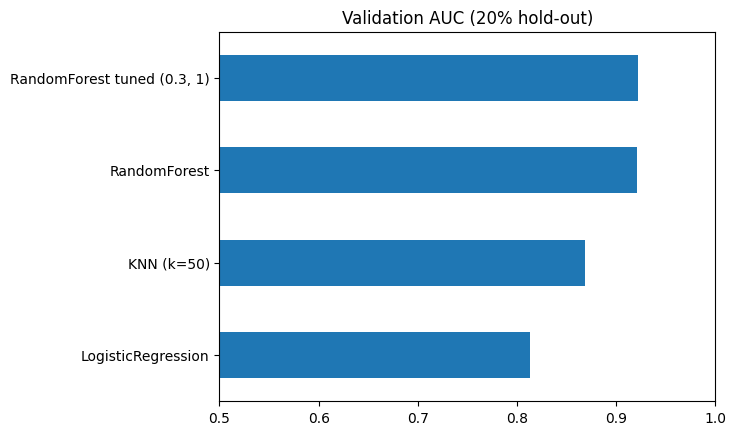

In [89]:
results[f'RandomForest tuned ({best_mf}, {best_msl})'] = rf_results[(best_mf, best_msl)]
pd.Series(results).sort_values().plot(kind='barh', title='Validation AUC (20% hold-out)', xlim=(0.5, 1));
pd.Series(results).sort_values(ascending=False).round(4)

### 4.2 Decision rule and class imbalance

The `sample_submission` asks for one **class** per row (not probabilities). If Kaggle computes the AUC from labels, the AUC of each class becomes $\frac{TPR + TNR}{2}$ (*balanced accuracy*): mistakes on the minority class (*Good*, 18%) weigh as much as on the majority class.

With `argmax` the model tends to predict *Standard* (the most frequent class). To compensate, each probability is divided by the frequency of its class before choosing:

$$\hat{y} = \arg\max_k \frac{P(k \mid x)}{\pi_k^{\alpha}}$$

where $\pi_k$ is the proportion of class $k$ in train and $\alpha$ controls the correction ($\alpha=0$ is the normal `argmax`, $\alpha=1$ full correction). $\alpha$ is chosen on the validation set.

In [95]:
best_rf = rf_pipes[(best_mf, best_msl)]   # already trained during tuning
p_va = best_rf.predict_proba(X_va)
priors = np.bincount(y_tr) / len(y_tr)

def auc_labels(y_true, labels, n_classes=3):
    # AUC obtained when submitting labels (one-hot) instead of probabilities
    eye = np.eye(n_classes)
    return roc_auc_score(eye[y_true], eye[labels], average='macro')

alpha_results = {}
for alpha in [0, 0.25, 0.5, 0.75, 1.0]:
    pred = (p_va / priors**alpha).argmax(axis=1)
    alpha_results[alpha] = auc_labels(y_va, pred)
    print(f'alpha={alpha:<5} AUC(labels)={alpha_results[alpha]:.4f}  '
          f'% predicted per class={np.round(np.bincount(pred, minlength=3) / len(pred), 3)}')

best_alpha = max(alpha_results, key=alpha_results.get)
print(f'AUC with probabilities = {auc(y_va, p_va):.4f} | best alpha = {best_alpha}')

alpha=0     AUC(labels)=0.8435  % predicted per class=[0.177 0.306 0.517]
alpha=0.25  AUC(labels)=0.8536  % predicted per class=[0.192 0.317 0.491]
alpha=0.5   AUC(labels)=0.8612  % predicted per class=[0.206 0.327 0.467]
alpha=0.75  AUC(labels)=0.8661  % predicted per class=[0.222 0.334 0.444]
alpha=1.0   AUC(labels)=0.8706  % predicted per class=[0.238 0.343 0.419]
AUC with probabilities = 0.9214 | best alpha = 1.0


## Part 5 — Final model and submission

1. Stratified 3-fold cross-validation to confirm the AUC is stable (does not depend on a single split).
2. Retraining on the **whole** training set.
3. Prediction on the test set and creation of `submission.csv`.

We use **300 trees**, the same number used during tuning: in Random Forest the AUC stabilizes after a few hundred trees, and adding more only increases computation time.

In [91]:
final_model = make_pipe(RandomForestClassifier(n_estimators=300, max_features=best_mf, min_samples_leaf=best_msl,
                                               n_jobs=-1, random_state=SEED))

# 3 stratified folds: each fold trains on 2/3 of the data and evaluates on the remaining 1/3
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(final_model, X, y, cv=cv, scoring='roc_auc_ovr')
print('AUC per fold:', cv_scores.round(4))
print(f'CV AUC = {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

AUC per fold: [0.9172 0.9161 0.9172]
CV AUC = 0.9168 ± 0.0005


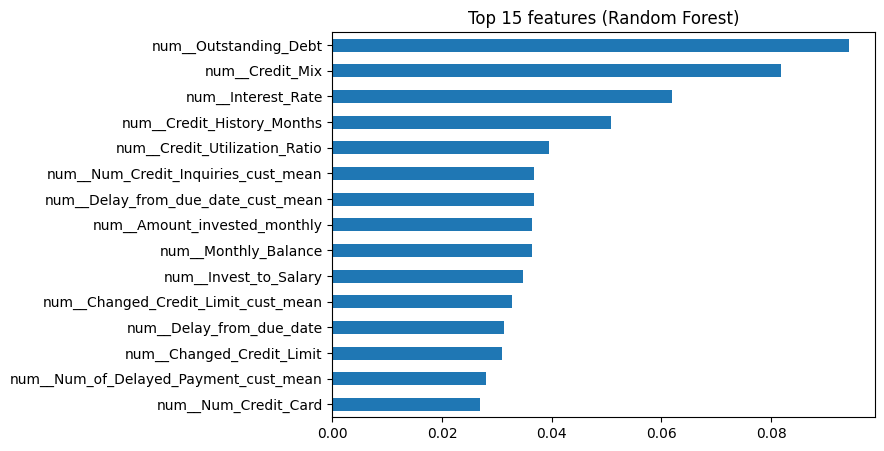

In [92]:
final_model.fit(X, y)

# Feature importance (mean decrease in Gini impurity)
feat_names = final_model.named_steps['pre'].get_feature_names_out()
importances = pd.Series(final_model.named_steps['model'].feature_importances_, index=feat_names)
importances.sort_values().tail(15).plot(kind='barh', figsize=(7, 5), title='Top 15 features (Random Forest)');

In [93]:
proba_test = final_model.predict_proba(X_test)                     # probabilities (30000 x 3)
pred_test = (proba_test / priors**best_alpha).argmax(axis=1)        # decision rule from section 4.2

submission = sample.copy()                                         # same columns and ids as the sample: id, class
submission['class'] = le.inverse_transform(pred_test)              # 0/1/2 -> Good/Poor/Standard
submission.to_csv('submission.csv', index=False)

print(submission['class'].value_counts(normalize=True).round(3))
submission.head()

class
Standard    0.421
Poor        0.348
Good        0.231
Name: proportion, dtype: float64


,id,class
0,1,Good
1,2,Poor
2,3,Good
3,4,Poor
4,5,Good


## Summary

| Stage | Decision |
|---|---|
| Cleaning | Remove `_` from numbers, garbage categories → NaN, impossible outliers → NaN |
| Imputation | Mode/median **of the same customer** (each customer appears in several months) |
| Features | Credit history in months, loan-type multi-hot, financial ratios, customer averages |
| Baseline | Logistic Regression |
| Experiments | KNN and Random Forest |
| Final model | **Random Forest** with tuned hyperparameters, validated with hold-out and 3-fold CV |

### Mathematical foundation of the final model (Random Forest)

- **Input:** feature vector $x$ of an application. **Output:** probability of each class $P(k \mid x)$, $k \in \{Good, Poor, Standard\}$.
- Each tree splits the data by choosing the feature and threshold that most reduce the **Gini impurity** of a node:
$$G = 1 - \sum_{k=1}^{K} p_k^2$$
where $p_k$ is the proportion of samples of class $k$ in the node. The chosen split maximizes $\Delta G = G_{parent} - \left(\frac{n_L}{n} G_L + \frac{n_R}{n} G_R\right)$.
- **Randomness:** each tree is trained on a bootstrap sample and at each split only considers `max_features` variables → different, weakly correlated trees.
- **Prediction:** average of the probabilities of the $T$ trees:
$$P(k \mid x) = \frac{1}{T} \sum_{t=1}^{T} p_t(k \mid x)$$
Averaging reduces the variance (overfitting) of a single tree. The final class is then chosen with the decision rule of section 4.2.